# Q-Ripple: can graph context improve illicit transaction detection?

Elliptic is an anonymised Bitcoin transaction graph: nodes are transactions and directed edges represent Bitcoin flow. We classify illicit versus licit transactions and rank risk on held-out labelled roots. Unknown-label nodes remain available as graph context, but do not become negative test labels.

We ask which additional information helps, and whether a quantum representation helps beyond a matched classical representation. The **same four cumulative cases** appear throughout the notebook, README and slides, for **Local 93 and All 165**:

| Case | Numerical inputs retained by every RF readout | Optional kernel branch |
|---|---|---|
| 1. Raw attributes | All 93 / 165 root attributes | RBF or quantum encoding of those attributes |
| 2. + Propagation | Case 1 plus full-period propagation descriptors | RBF or quantum encoding of propagation descriptors |
| 3. + Spectral topology | Case 2 plus unencoded spectral/topology descriptors | RBF or quantum encoding of the same descriptors |
| 4. + Direct topology | **Entire case-3 vector retained unchanged** | Adjacency RBF or a graph-dependent Hamiltonian circuit |

Each case has three arms: **RF only**, **Classical RBF + RF**, and **Quantum circuit + RF**. Raw RF is a shared reference; the attribute quantum kernel is not a quantum Random Forest. “Classical equivalent” means matched input information and RF settings, not an identical similarity function. Comparing case 3 and case 4 tests a different topology branch while preserving the numerical topology already available.

## Protocol and what each comparison answers

**Feature sets.** Local contains 93 root attributes. All adds 72 supplied neighborhood aggregates, so it already includes some graph information. The time-step field controls splitting and is excluded from the 93/165 numerical inputs.

**Shared cohorts.** Train on steps 1–30, validate on 31–34, and test on 35–49. All four cases use the same 80/60/100 train/validation/test roots per seed over seeds 42/43/44. Graph models reveal a fixed 20% of period-local illicit labels as known risk seeds and exclude them from evaluation throughout. Unknown nodes and full-period connectivity remain available. This is seed-assisted discovery with the period graph known, not an online edge-arrival evaluation.

**A common four-hop radius** applies to cases 2–4, with an eight-node budget for sampled topology. This removes the previous confounding between adding features and changing hop radius. Full-period propagation remains uncapped. Case 4 uses a real simulator sweep of 1/2/4/8 product-formula steps; numerical quantum encoders try one/two passes. Mean validation AP selects the quantum configuration per case and feature set, and its exact RBF counterpart is retained. RF-only controls remain visible rather than disappearing when another model wins validation AP. Passes/steps shown on an RBF row identify its paired quantum configuration; RBF itself has no quantum depth.

**Information question:** compare the RF-only controls across cases. **Representation question:** compare RF-only, RBF and circuit arms within a case. **Execution question:** evaluate the same graph circuit noiselessly or on IBM hardware, keeping this secondary to the circuit-versus-no-circuit comparisons.

Transforms and 12 landmark indices are fitted/chosen on training data only. Every kernel uses the same Nyström construction and RF settings within its pair. Test scores select nothing. The cohort is small and repeatedly explored; general claims need a new confirmatory holdout.

The primary cumulative fits are stored separately under `07_*`, with hardware reanalysis under `08_*`. Earlier `01_*`–`06_*` searches retain their original results and should not be mixed into the new tables: those models did not retain the spectral bypass in the direct-topology arm. `REUSE_SAVED_RESULTS=True` restores matching cumulative fits; set it to `False` after changes to modelling code or to rerun training.

## Metrics: what each score measures

The positive class is **illicit**. Let TP, FP, TN and FN denote true/false positives and negatives. Every classification table uses the same five test metrics, with higher values better:

| Metric | Definition | Why report it? |
|---|---|---|
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ | Overall correctness; can look high when most transactions are licit. |
| Balanced accuracy | $\tfrac12[TP/(TP+FN)+TN/(TN+FP)]$ | Weights illicit recall and licit recall equally, exposing majority-class shortcuts. |
| Illicit F1 | $2TP/(2TP+FP+FN)$ | Balances illicit precision and recall at the classifier's decision threshold. |
| PR-AUC (AP) | $\sum_k(R_k-R_{k-1})P_k$ over score thresholds | Average precision evaluates illicit ranking. Its random-ranking reference is approximately the illicit fraction. |
| ROC-AUC | Probability that a random illicit case outranks a random licit case, with ties half-weighted | Measures ranking across both classes; may look strong despite weak precision under imbalance. |

“PR-AUC” in this project means scikit-learn **average precision**, not trapezoidal integration of a PR curve. AP and ROC-AUC use probabilities/ranking scores; accuracy, balanced accuracy and F1 use predicted classes (RF's usual decision rule). Validation AP is a selection score, not an additional test metric.

AP depends on prevalence: compare matched simulator cohorts, and report the small balanced hardware pilot separately. AP SD and plot error bars describe variation over three sampling seeds, **not** confidence intervals or shot uncertainty. Similarity, relabeling error and observable noise are diagnostics, so classification accuracy is not meaningful for those tables.

Metric heatmaps share a 0–1 color scale. Configuration heatmaps use an explicitly labelled focused validation-AP scale; gray means an unevaluated combination. Line plots fit the observed values and error bars rather than forcing a 0–1 y-axis.

Definitions: [scikit-learn classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics), [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

In [1]:
from pathlib import Path
import sys
ROOT = next(p.resolve() for p in [Path.cwd(), Path.cwd() / 'q-ripple-elliptic']
            if (p / 'elliptic_models').is_dir())
sys.path.insert(0, str(ROOT))
from elliptic_models import ExperimentFlow, FourCaseStudy

REUSE_SAVED_RESULTS = True
COMMON_HOPS = 4
HAMILTONIAN_STEPS = (1, 2, 4, 8)
HARDWARE = dict(attributes=False, propagation=False,
                topology_features=False, quantum_topology=True)
flow = ExperimentFlow(ROOT).prepare()
four = FourCaseStudy(flow, hops=COMMON_HOPS, passes=(1, 2), steps=HAMILTONIAN_STEPS)
four.run(reuse_saved=REUSE_SAVED_RESULTS).reports();

Simulator cohorts ready: {'train': 80, 'val': 60, 'test': 100}; 3 sampling seeds. All four stages share roots.
Full and selected tables: /Users/gigileung/git-qiskit/qiskit_fall_fest_warsaw/q-ripple-elliptic/results/experiment_flow
Restored cumulative four-case simulator fits.


## 1. Raw attributes: RF, classical kernel and quantum kernel

Raw RF establishes the no-added-context reference. The two kernel arms append coordinates to the **same complete raw vector** before fitting an otherwise identical RF. Their RBF and quantum maps receive the same 93 or 165 attributes, transformed with train-only standardisation and $2\arctan(x)$, without PCA.

The RBF kernel measures numerical proximity: $K_C(x,x')=\exp[-\gamma\|x-x'\|^2]$. Quantum re-uploading prepares a state $|\phi(x)\rangle$ and computes $K_Q(x,x')=|\langle\phi(x)|\phi(x')\rangle|^2$. Four qubits receive all input angles in chunks, with one/two complete passes tested.

**Nyström** converts either kernel into coordinates using the same 12 training landmarks: $\Phi(x)=K(x,L)K(L,L)^{\dagger/2}$ on the retained positive eigenspace. It reduces kernel evaluation cost and does not create new information. The RF also sees every original input unchanged. We test representation rather than claiming a quantum RF implementation.

,Case,Features,Arm,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
0,1 Raw attributes,Local,RF only,Raw RF,raw attributes,0.9267,0.8667,0.5385,0.7383,0.8940,0.6153,3,0.1965
1,1 Raw attributes,Local,Classical RBF,RF + RBF attributes,raw attributes; passes=1,0.9300,0.8684,0.5606,0.7722,0.8702,0.6251,3,0.1303
2,1 Raw attributes,Local,Quantum circuit,RF + quantum attributes,raw attributes; passes=1,0.9367,0.8404,0.5493,0.7417,0.8653,0.5997,3,0.2357
3,1 Raw attributes,All,RF only,Raw RF,raw attributes,0.9333,0.8702,0.5423,0.8054,0.8779,0.5912,3,0.1719
4,1 Raw attributes,All,Classical RBF,RF + RBF attributes,raw attributes; passes=1,0.9567,0.8825,0.6815,0.7905,0.8772,0.5829,3,0.2304
5,1 Raw attributes,All,Quantum circuit,RF + quantum attributes,raw attributes; passes=1,0.9467,0.8772,0.5977,0.7961,0.8716,0.5829,3,0.1608


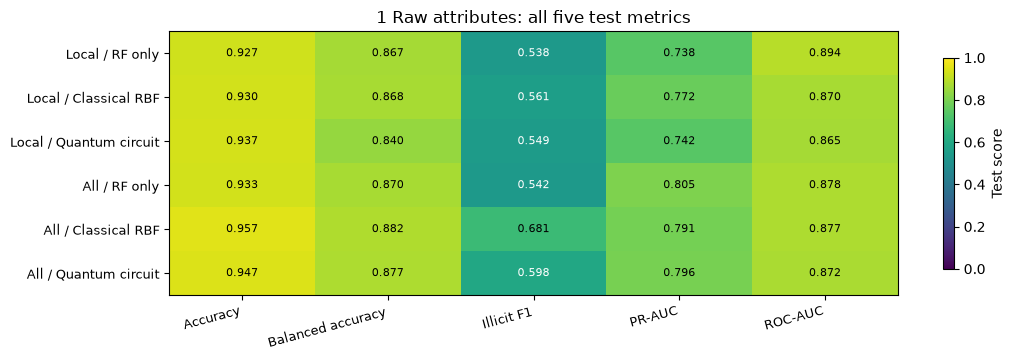

In [2]:
four.case(1);

## 2. Add propagation while retaining the attributes

Known-illicit seeds supply risk context. Direction-specific averaging operators propagate seed signals along transaction walks: quantities like $P^k s$ measure predecessor/successor exposure at length $k$. Walks may revisit nodes, so these are not exact shortest-path shells.

The four-hop feature group retains the legacy nine descriptors, full-period structural information and directional walk profiles. Both kernel branches see the **same whole propagation descriptor vector**; neither needs the quantum circuit to obtain this information. RF-only sees raw attributes plus these unencoded descriptors. The RBF and generic re-uploading quantum arms append their respective propagation coordinates to that same RF input.

Compare with case 1 to judge added numerical information, and compare the three case-2 arms to judge the benefit of the chosen kernel.

,Case,Features,Arm,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
6,2 + Propagation,Local,RF only,RF + propagation,4 hops,0.9200,0.8632,0.5294,0.7973,0.8772,0.6284,3,0.1608
7,2 + Propagation,Local,Classical RBF,RF + RBF propagation,4 hops; passes=1,0.9533,0.8807,0.6405,0.8040,0.8912,0.5989,3,0.1865
8,2 + Propagation,Local,Quantum circuit,RF + quantum propagation,4 hops; passes=1,0.9633,0.8860,0.6869,0.7790,0.8898,0.5838,3,0.2480
9,2 + Propagation,All,RF only,RF + propagation,4 hops,0.9400,0.8737,0.5757,0.7830,0.8737,0.5969,3,0.1426
10,2 + Propagation,All,Classical RBF,RF + RBF propagation,4 hops; passes=1,0.9367,0.8719,0.5707,0.8159,0.8744,0.5906,3,0.1882
11,2 + Propagation,All,Quantum circuit,RF + quantum propagation,4 hops; passes=1,0.9433,0.8754,0.6028,0.8167,0.8730,0.5837,3,0.1887


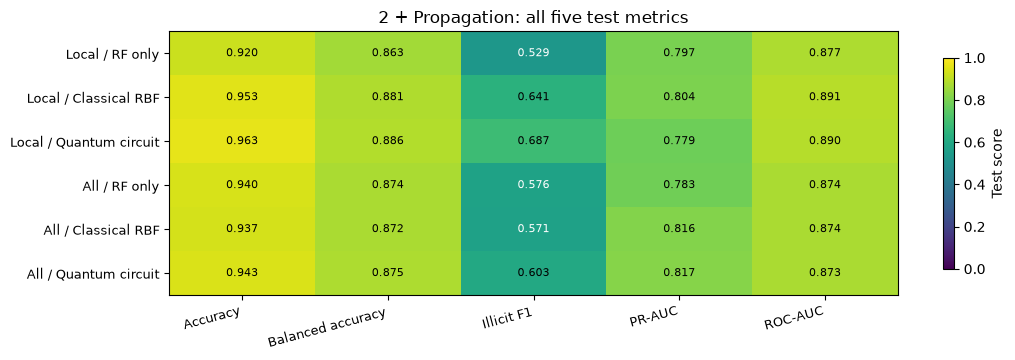

In [3]:
four.case(2);

## 3. Add numerical topology: spectral features are topology features

**Spectral features are one specific numerical description of topology.** In this notebook the spectral vector contains motif/degree/walk summaries, undirected-adjacency eigenvalues, directed-adjacency singular values and root return-walk information. It is not a separate topic from topology. The vector describes a sampled rooted graph but is not a complete graph invariant.

Sample up to eight nodes within the shared four-hop radius, preserving root/known-seed markers. Add the entire unencoded descriptor vector to the complete case-2 numerical input. RF-only can therefore exploit topology directly. The classical RBF and quantum rotation kernels both receive the same descriptor vector and append their coordinates to that same retained input.

**Here the quantum circuit encodes a description of connectivity.** Graph edges do not choose its gate connections. Two graphs with identical selected descriptors remain identical to these descriptor kernels, regardless of how expressive their rotations are. Earlier rooted-WL and motif-only searches remain in the exploratory CSVs; the primary four-case comparison consistently uses this spectral descriptor family for both Local and All.

,Case,Features,Arm,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
12,3 + Spectral topology,Local,RF only,RF + propagation + spectra,4 hops,0.9400,0.8737,0.6139,0.7929,0.8821,0.6207,3,0.1536
13,3 + Spectral topology,Local,Classical RBF,RF + RBF spectra,4 hops; passes=2,0.9500,0.8474,0.6000,0.7482,0.8933,0.6141,3,0.2292
14,3 + Spectral topology,Local,Quantum circuit,RF + quantum spectra,4 hops; passes=2,0.9633,0.8544,0.6556,0.7295,0.8877,0.6406,3,0.2223
15,3 + Spectral topology,All,RF only,RF + propagation + spectra,4 hops,0.9433,0.8754,0.5897,0.7888,0.8821,0.5735,3,0.1977
16,3 + Spectral topology,All,Classical RBF,RF + RBF spectra,4 hops; passes=1,0.9433,0.8754,0.5850,0.7871,0.8730,0.6107,3,0.1976
17,3 + Spectral topology,All,Quantum circuit,RF + quantum spectra,4 hops; passes=1,0.9567,0.8825,0.6496,0.7881,0.8751,0.6077,3,0.1985


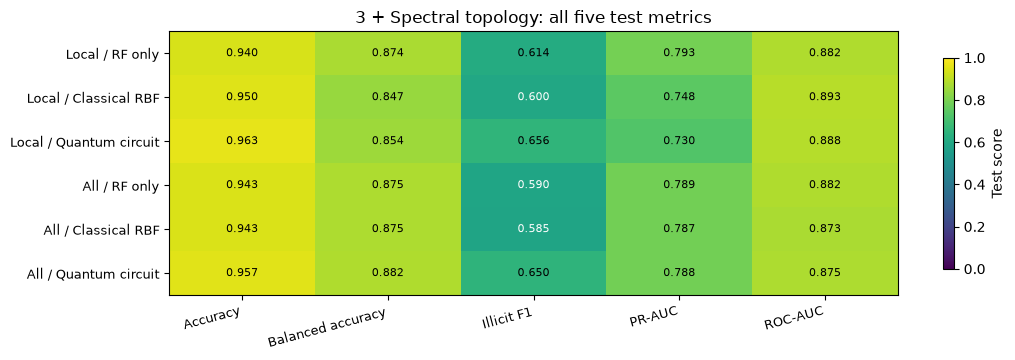

In [4]:
four.case(3);

## 4. Add a graph-dependent circuit, with all earlier numerical inputs retained

**Direct quantum topology** receives the retained adjacency matrix, active-node mask and root/seed markers. Actual edges determine circuit interactions, rather than becoming only numerical summary values. For the Hamiltonian model,

$$H_G=0.37\sum_iY_i+0.7\sum_{i\rightarrow j}Z_iX_j,\qquad |\psi_G(t)\rangle\approx U_r(t)|\psi_{\mathrm{root,seed}}\rangle,\quad t=0.8.$$

The state-fidelity kernel measures similarities between these graph-dependent states. A symmetric second-order product formula approximates the evolution. Sweeping 1/2/4/8 steps changes approximation accuracy and circuit cost at fixed time, not hop radius. All of these fits run on the simulator.

**The matched classical control remains possible because the same adjacency is available classically.** Pack $x_G=[\mathrm{mask},\mathrm{root},\mathrm{seeds},0,\mathrm{vec}(A)]$ and compute an adjacency RBF kernel. The zero block is the unused node-attribute-angle block. Its roots, ordering, masks, seeds, node budget, landmarks and downstream RF settings match the quantum arm. A deterministic ordering is not a canonical graph labeling; both representations retain possible ordering sensitivity.

**All three arms keep raw Local/All attributes, full-period propagation and the complete unencoded spectral vector.** RF-only is therefore identical to case-3 RF-only. The RBF arm adds adjacency similarities, and the quantum arm adds Hamiltonian similarities. This tests whether the graph-dependent circuit helps beyond not using it, including beyond numerical topology. Finite sampling/registers and Nyström still introduce approximations; retaining numerical inputs does not make quantum encoding lossless.

A noiseless simulator and IBM hardware are two ways to evaluate a quantum feature map. The primary comparison is **RF / classical RBF versus using the quantum circuit**. Ideal-versus-device discrepancies are secondary execution diagnostics, not the main claim of predictive value.

,Case,Features,Arm,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
18,4 + Direct topology,Local,RF only,RF + propagation + spectra,4 hops,0.9400,0.8737,0.6139,0.7929,0.8821,0.6207,3,0.1536
19,4 + Direct topology,Local,Classical RBF,RF + adjacency RBF,4 hops; steps=2,0.9600,0.8526,0.6528,0.7052,0.8800,0.6253,3,0.2422
20,4 + Direct topology,Local,Quantum circuit,RF + Hamiltonian circuit,4 hops; steps=2,0.9733,0.8596,0.7249,0.7488,0.8807,0.6304,3,0.2429
21,4 + Direct topology,All,RF only,RF + propagation + spectra,4 hops,0.9433,0.8754,0.5897,0.7888,0.8821,0.5735,3,0.1977
22,4 + Direct topology,All,Classical RBF,RF + adjacency RBF,4 hops; steps=8,0.9467,0.8456,0.5818,0.7775,0.8744,0.6199,3,0.1355
23,4 + Direct topology,All,Quantum circuit,RF + Hamiltonian circuit,4 hops; steps=8,0.9600,0.8842,0.6623,0.8164,0.8814,0.5981,3,0.1874


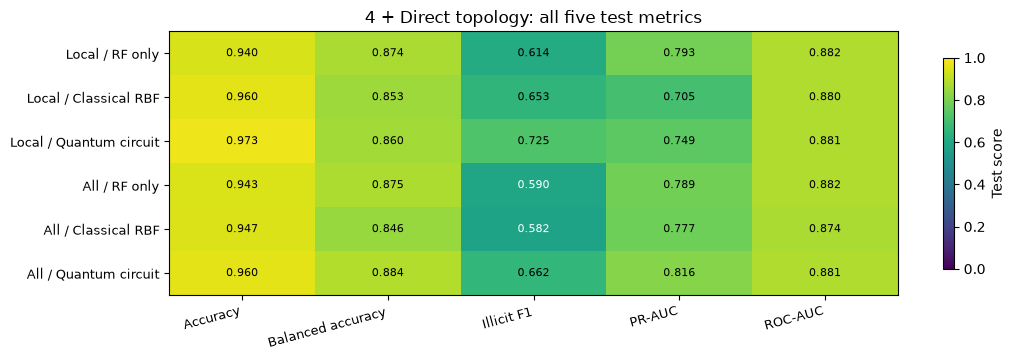

In [5]:
four.case(4);

### Structural and similarity diagnostics

Before interpreting predictive gains, ask whether selected summaries collide on different graphs and whether encodings respond consistently to node relabeling. The cube/Möbius-ladder test has no illicit classification labels, so similarity and relabeling error are its outcomes. Classical spectral/WL controls can distinguish structures that chosen counts miss; this does not establish a uniquely quantum distinction.

The training-kernel heatmaps illustrate summary-RBF/summary-quantum and adjacency-RBF/Hamiltonian similarities on the same roots. They use four Hamiltonian steps as an illustrative setting, while the primary case-4 step count is validation-selected. A different heatmap alone is not evidence of improved classification.

,Encoder,Different graph similarity,Isomorphic mean similarity,Mean relabeling error
11,Classical summary RBF,1.0000,1.0000,0.0000
12,Classical spectral RBF,0.6179,1.0000,0.0000
13,Quantum summary rotations,1.0000,1.0000,0.0000
19,Quantum Hamiltonian invariant moments (product),0.9735,0.9996,0.0004
21,Classical rooted WL,0.8577,1.0000,0.0000


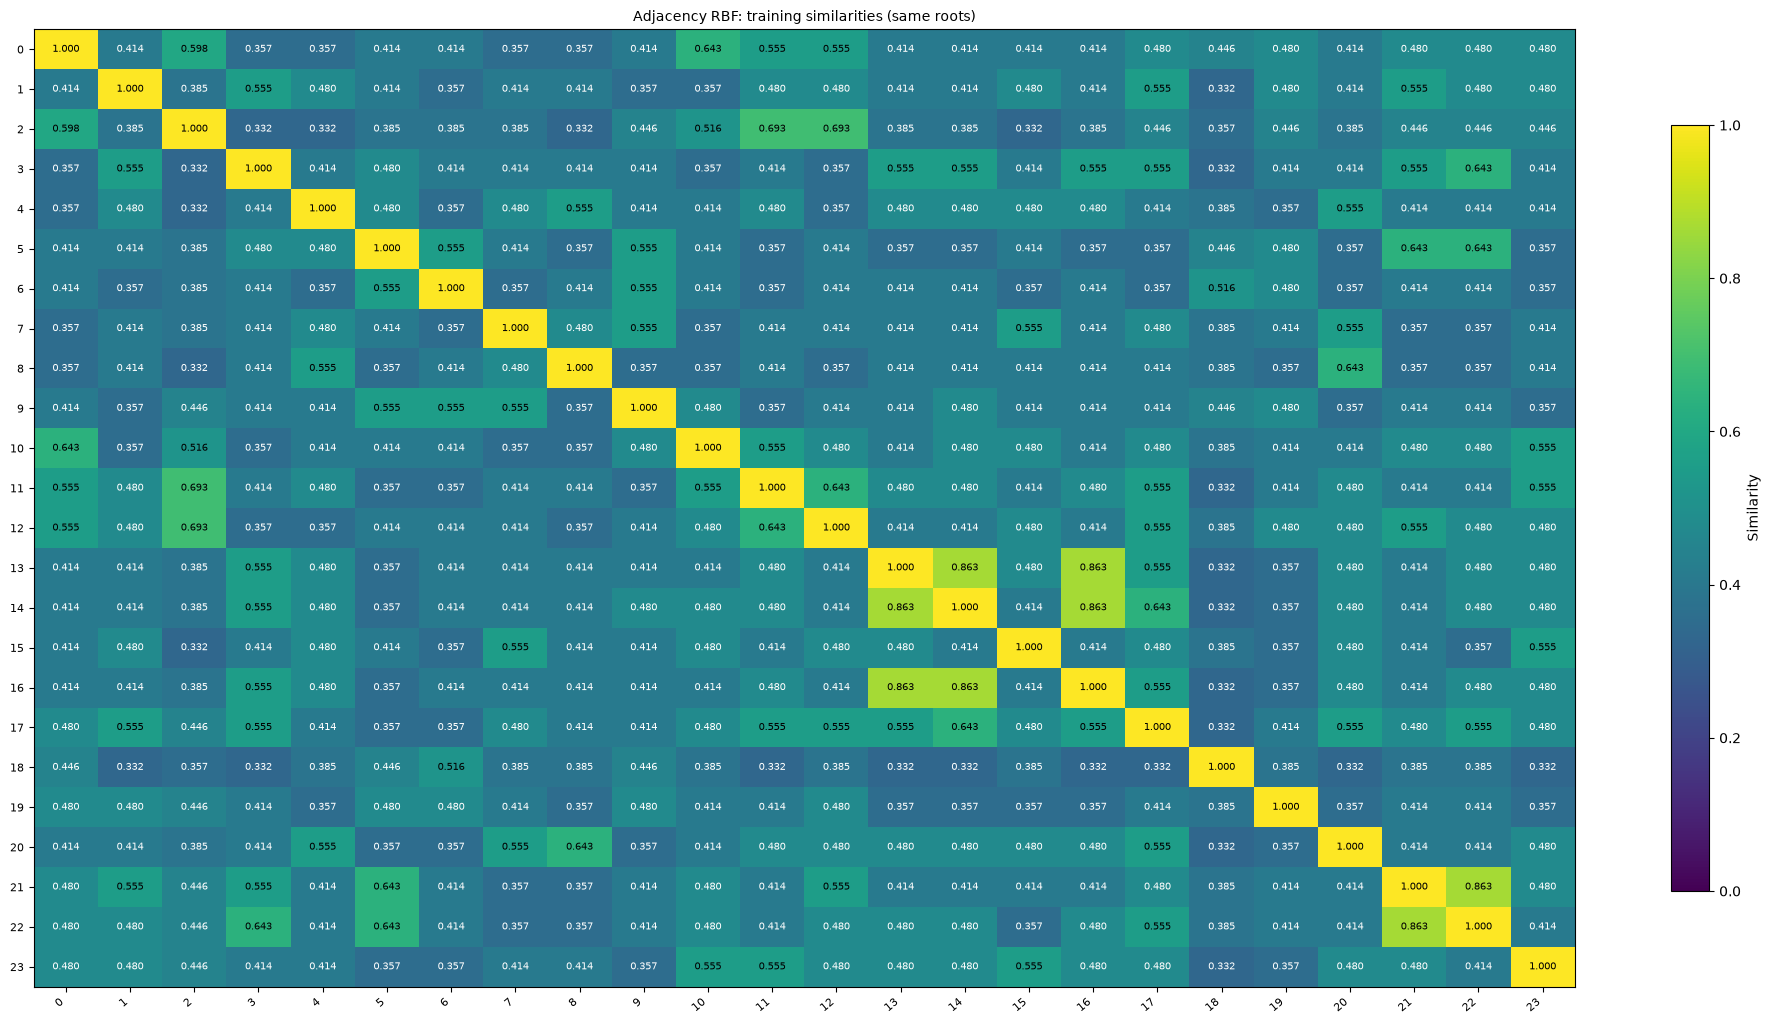

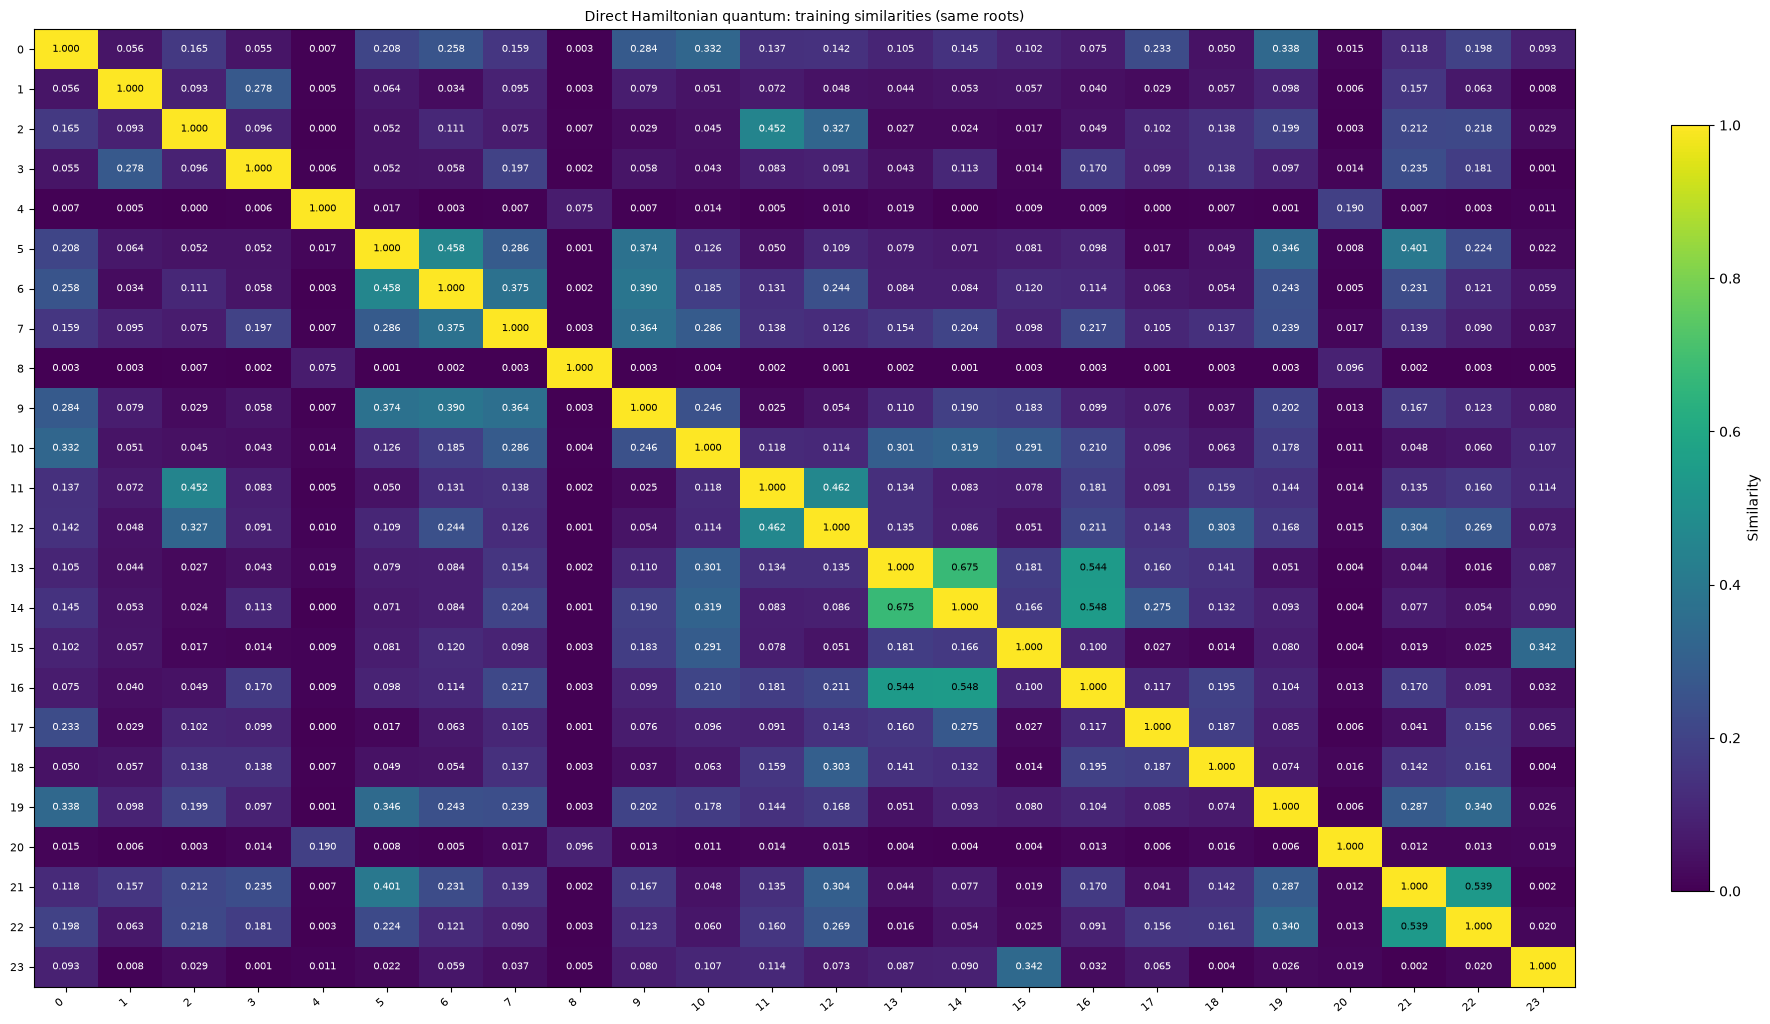

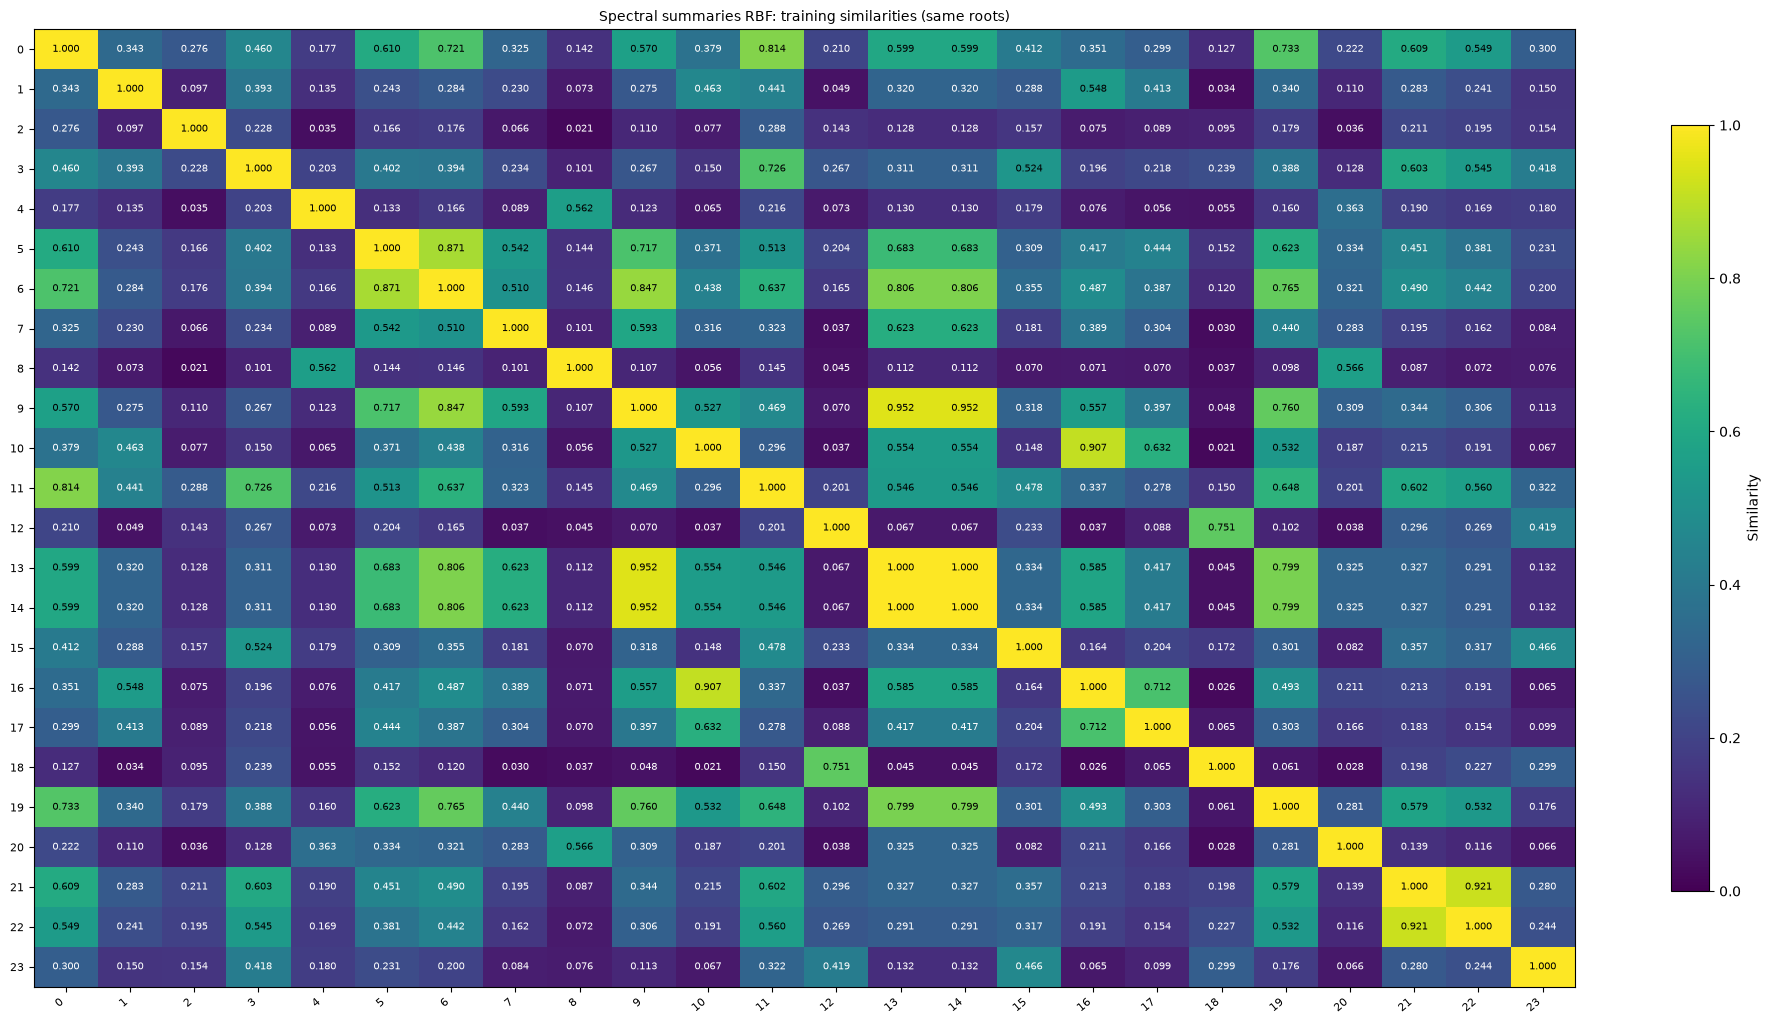

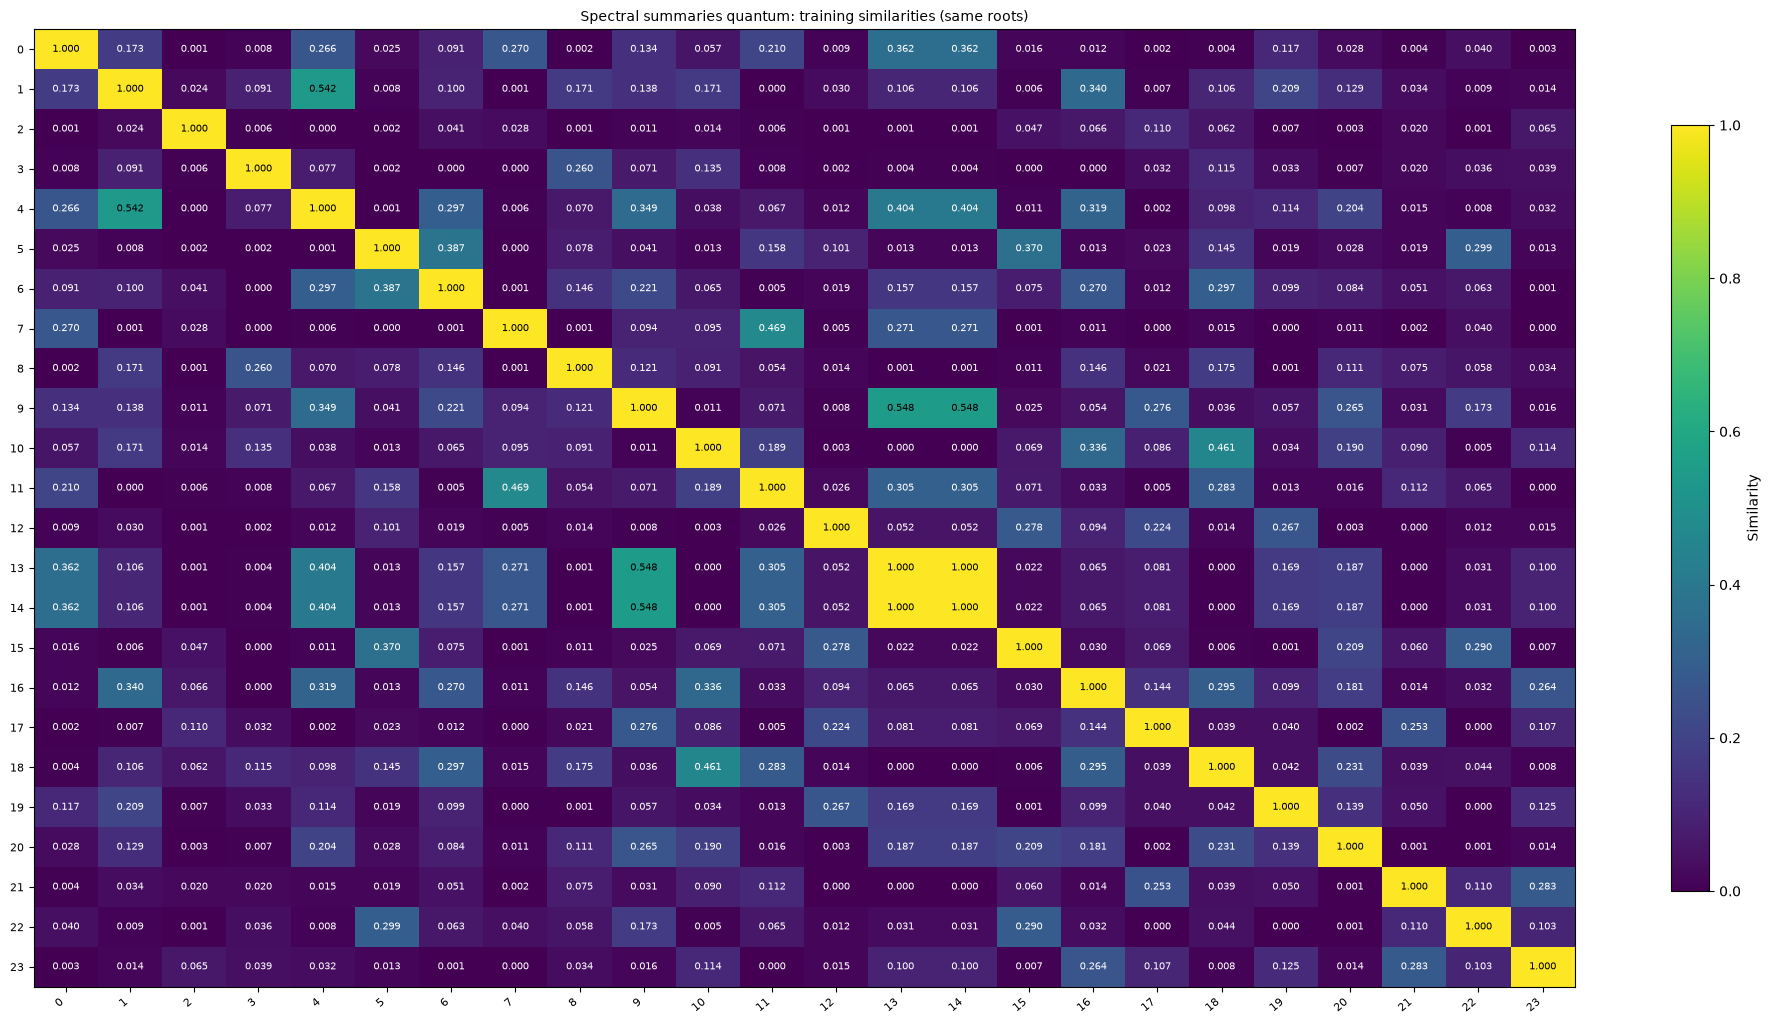

In [6]:
flow.structural_check()
flow.kernel_heatmaps(hops=COMMON_HOPS, count=24)

## IBM pilot: does using the circuit beat the non-circuit controls?

The separate balanced hardware cohort has 12 train / 8 validation / 12 test examples. Refit **all four cases for Local and All** on those exact roots. Keep RF-only and RBF arms beside simulator quantum arms throughout, and add the **IBM-measured graph circuit only in case 4**. Compare the device arm with raw RF, propagation, spectral RF and adjacency RBF first. Noiseless versus IBM then describes execution effects for the final circuit.

Most IBM runs remain disabled: attribute, propagation and numerical-topology quantum arms are simulator-only. Only the final graph-dependent circuit has physical measurements. We reuse the two completed IBM jobs and their recorded landmark kernels. Because those circuits receive topology and markers without numerical node attributes, their measured similarities can be reused for Local/All and for the new spectral RF bypass. **No new jobs are submitted by this reanalysis.** The original preparation/submission/recovery methods remain in `HamiltonianHardwareExperiment` for future final-topology execution.

The new readout scores can differ from the earlier four-row IBM table because the classifier now also retains numerical spectral features. Balanced prevalence and the tiny cohort prevent direct AP comparison with the main simulator cohort. Within the hardware pilot, every arm uses the same roots and class balance. Treat any observed gain as exploratory, not established statistical significance.

In [7]:
hardware_results = four.hardware() if HARDWARE['quantum_topology'] else None

,Case,Features,Arm,Model,Execution,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
0,1 Raw attributes,Local,RF only,Raw RF,Classical,raw attributes,0.6667,0.6667,0.7143,0.9167,0.8472,0.8929,1,NaN
1,1 Raw attributes,Local,Classical RBF,RF + RBF attributes,Classical,raw attributes; passes=1,0.6667,0.6667,0.7143,0.8357,0.8056,0.8750,1,NaN
2,1 Raw attributes,Local,Quantum circuit,RF + quantum attributes,Noiseless simulator,raw attributes; passes=1,0.6667,0.6667,0.7143,0.8357,0.8056,0.8750,1,NaN
3,1 Raw attributes,All,RF only,Raw RF,Classical,raw attributes,0.7500,0.7500,0.7692,0.9583,0.9444,0.8750,1,NaN
4,1 Raw attributes,All,Classical RBF,RF + RBF attributes,Classical,raw attributes; passes=1,0.7500,0.7500,0.6667,0.7827,0.6667,0.8929,1,NaN
5,1 Raw attributes,All,Quantum circuit,RF + quantum attributes,Noiseless simulator,raw attributes; passes=1,0.7500,0.7500,0.6667,0.8631,0.8056,0.9167,1,NaN
6,2 + Propagation,Local,RF only,RF + propagation,Classical,4 hops,0.6667,0.6667,0.7143,0.6190,0.5972,0.8125,1,NaN
7,2 + Propagation,Local,Classical RBF,RF + RBF propagation,Classical,4 hops; passes=1,0.6667,0.6667,0.7143,0.8135,0.7639,0.8750,1,NaN
8,2 + Propagation,Local,Quantum circuit,RF + quantum propagation,Noiseless simulator,4 hops; passes=1,0.6667,0.6667,0.7143,0.8135,0.7639,0.8750,1,NaN
9,2 + Propagation,All,RF only,RF + propagation,Classical,4 hops,0.8333,0.8333,0.8333,0.9167,0.8889,0.8750,1,NaN


**Hardware pilot:** all four cases use the same recorded balanced 12/8/12 roots; Local and All are both included. Compare each circuit arm with the RF and RBF controls first. Noiseless and IBM execution are two implementations of the final graph circuit. Earlier quantum feature-map arms remain simulator-only; only case 4 has IBM measurements. The numerical spectral bypass is now retained, so these readout scores can differ from the earlier four-row hardware report. No circuits were resubmitted.

## Final summary: four cases, both feature sets, all five metrics

The table and plots use exactly the four cases above. Each Local/All case retains its RF-only control, matched classical RBF and validation-selected quantum arm. “Best” refers to validation AP over the tested passes/steps, not the largest test F1. Both AP and F1 curves show raw, propagation, spectral topology and direct topology for **both** feature sets. No hop changes are hidden between points.

RF-only curves isolate gains from adding numerical inputs. The final RF-only point repeats case 3 because its numerical inputs are identical. Compare case-4 RBF and circuit scores with this RF-only control to judge whether explicit connectivity adds value beyond spectra. The spectral-kernel and adjacency-kernel arms also differ in representation, so case 3 versus case 4 is not an isolated hardware-execution experiment.

The final plots also retain the full simulator step sweep at fixed four-hop radius. Focused y-ranges include the sampling error bars. All tables and plotted values are exported to CSV under `results/experiment_flow/`; `07_*` is the primary simulator study and `08_*` is the matched hardware-cohort reanalysis. Historical scores from the earlier non-cumulative search remain available, but are not substituted into these comparisons.

,Case,Features,Arm,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
0,1 Raw attributes,Local,RF only,Raw RF,raw attributes,0.9267,0.8667,0.5385,0.7383,0.8940,0.6153,3,0.1965
1,1 Raw attributes,Local,Classical RBF,RF + RBF attributes,raw attributes; passes=1,0.9300,0.8684,0.5606,0.7722,0.8702,0.6251,3,0.1303
2,1 Raw attributes,Local,Quantum circuit,RF + quantum attributes,raw attributes; passes=1,0.9367,0.8404,0.5493,0.7417,0.8653,0.5997,3,0.2357
3,1 Raw attributes,All,RF only,Raw RF,raw attributes,0.9333,0.8702,0.5423,0.8054,0.8779,0.5912,3,0.1719
4,1 Raw attributes,All,Classical RBF,RF + RBF attributes,raw attributes; passes=1,0.9567,0.8825,0.6815,0.7905,0.8772,0.5829,3,0.2304
5,1 Raw attributes,All,Quantum circuit,RF + quantum attributes,raw attributes; passes=1,0.9467,0.8772,0.5977,0.7961,0.8716,0.5829,3,0.1608
6,2 + Propagation,Local,RF only,RF + propagation,4 hops,0.9200,0.8632,0.5294,0.7973,0.8772,0.6284,3,0.1608
7,2 + Propagation,Local,Classical RBF,RF + RBF propagation,4 hops; passes=1,0.9533,0.8807,0.6405,0.8040,0.8912,0.5989,3,0.1865
8,2 + Propagation,Local,Quantum circuit,RF + quantum propagation,4 hops; passes=1,0.9633,0.8860,0.6869,0.7790,0.8898,0.5838,3,0.2480
9,2 + Propagation,All,RF only,RF + propagation,4 hops,0.9400,0.8737,0.5757,0.7830,0.8737,0.5969,3,0.1426


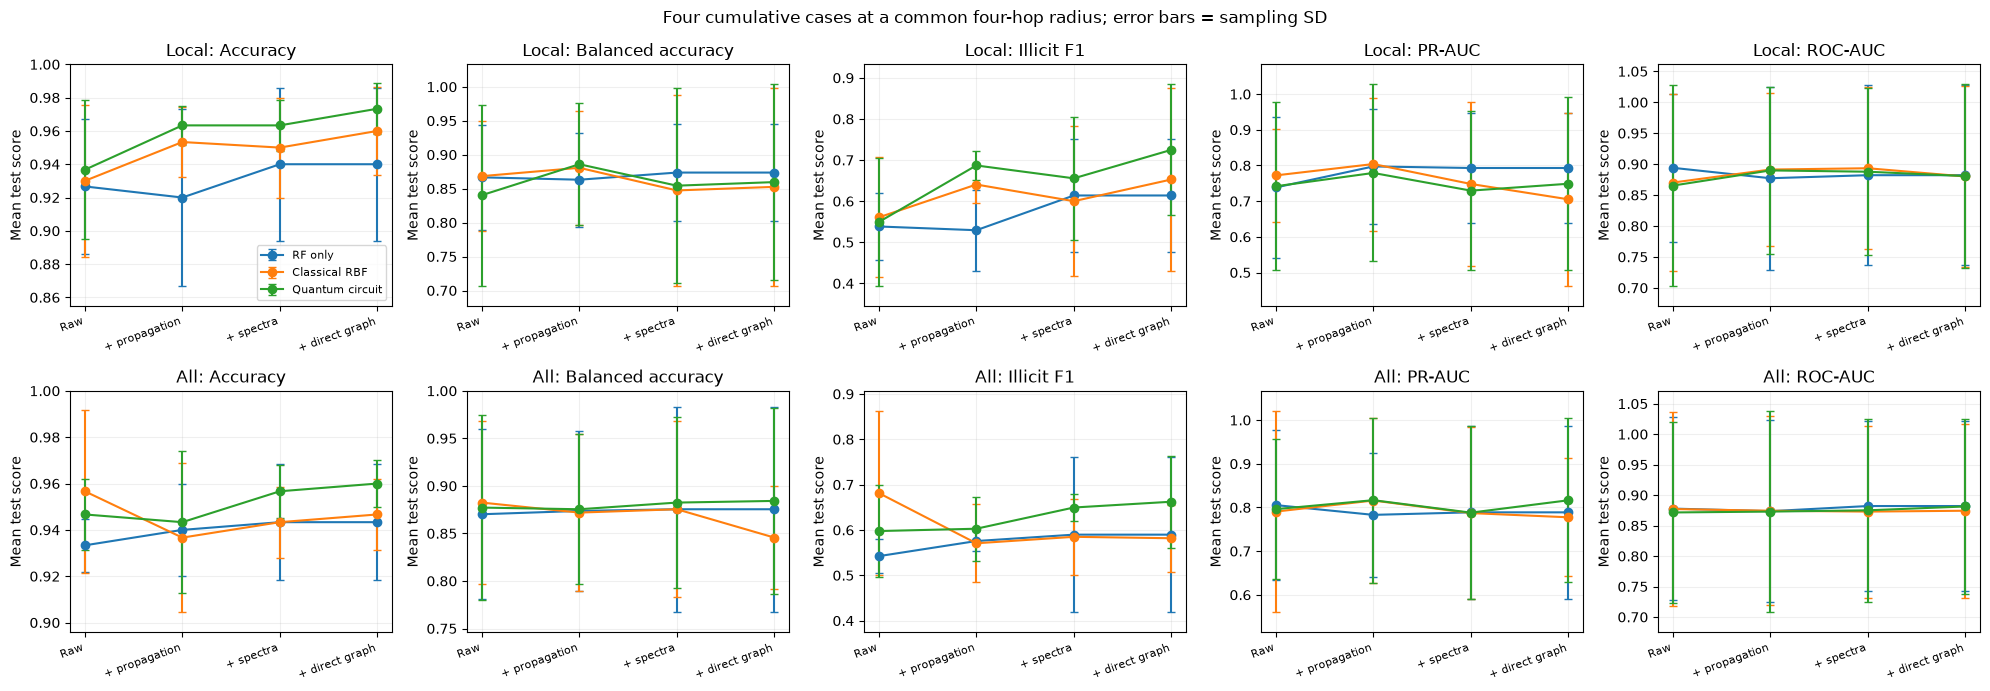

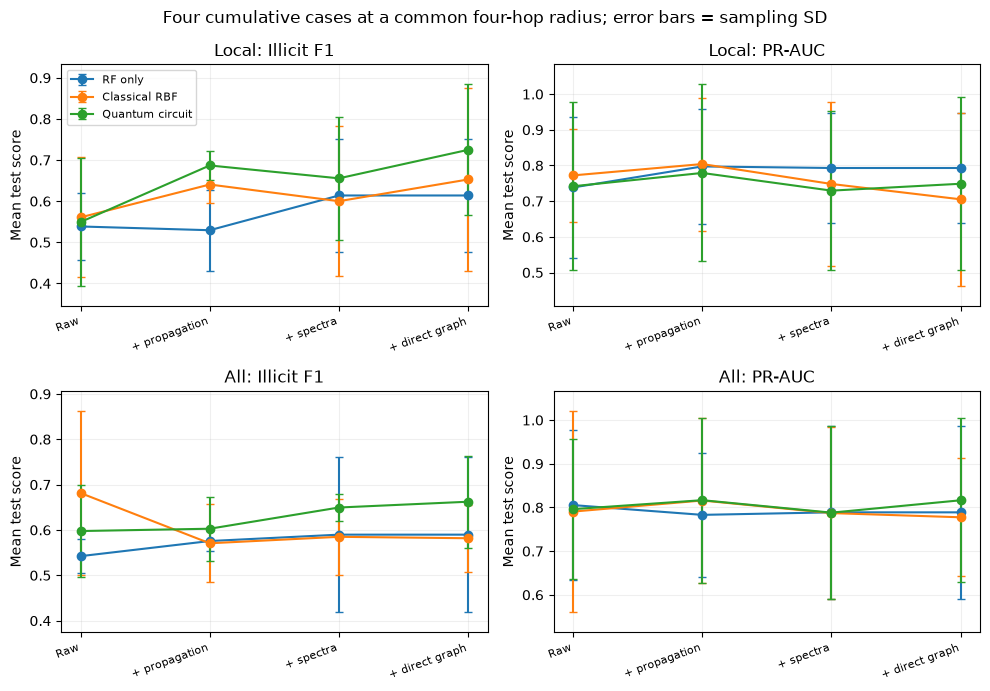

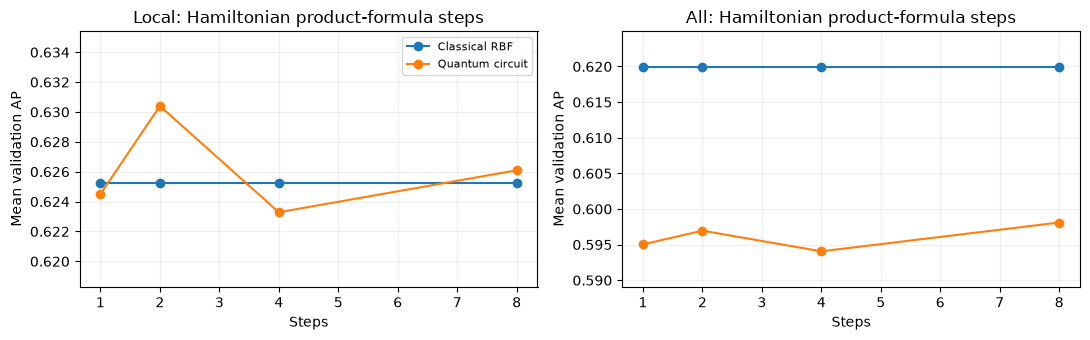

**Interpretation:** compare RF-only across cases for added numerical information, then compare the matched RBF and circuit arms for representation value. Case 4 retains the entire case-3 numerical vector in both arms. Main results use four hops throughout; older independently selected radii belong to the exploratory results, not these cumulative comparisons.

In [8]:
four.summary()